Add the project root path so notebook cells can import modules directly from src/:

In [1]:
import sys
from pathlib import Path

# Set project root (one level up from notebooks/)
PROJECT_ROOT = Path("..").resolve()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import torch
import torch.nn as nn
import torchvision.models as models
import matplotlib.pyplot as plt

from src.data.loaders import get_classification_loaders
from src.models.classifier import ImageClassifier
from src.training.trainer import get_device

device = get_device()
print(f"Active Device: {device}")

Active Device: cuda


Cell 2: Define Pretrained ResNet-18 Encoder ArchitectureConstruct the pretrained ResNet-18 visual encoder and wrap it inside ImageClassifier:   

In [2]:
class ResNet18Encoder(nn.Module):
    """Pretrained ResNet-18 feature extractor."""
    def __init__(self, pretrained=True):
        super().__init__()
        weights = models.ResNet18_Weights.DEFAULT if pretrained else None
        resnet = models.resnet18(weights=weights)
        # Retain feature maps up to final spatial convolution layer [B, 512, 7, 7]
        self.features = nn.Sequential(*list(resnet.children())[:-2])
        self.out_channels = 512

    def forward(self, x):
        return self.features(x)

# Instantiate transfer learning model
encoder = ResNet18Encoder(pretrained=True)
model = ImageClassifier(encoder, num_classes=200, dropout=0.3).to(device)

print(f"Model successfully loaded on {device}.")

Model successfully loaded on cuda.


Cell 3: Load Sample Validation BatchFetch a sample batch using get_classification_loaders:   

In [3]:
# Load data with num_workers=0 for interactive notebook stability
train_loader, val_loader, test_loader = get_classification_loaders(
    batch_size=8,
    num_workers=0,
    image_size=224
)

batch = next(iter(val_loader))
images = batch["image"]
labels = batch["label"]

print(f"Batch Image Tensor Shape: {images.shape}")
print(f"Batch Label Tensor Shape: {labels.shape}")

Batch Image Tensor Shape: torch.Size([8, 3, 224, 224])
Batch Label Tensor Shape: torch.Size([8])


Cell 4: Load Trained Checkpoint (Optional)If you have already trained model weights, load them for inference evaluation:   

In [4]:
checkpoint_path = PROJECT_ROOT / "outputs" / "checkpoints" / "cls_resnet18.pt"

if checkpoint_path.exists():
    model.load_state_dict(torch.load(checkpoint_path, map_location=device))
    print(f"Successfully loaded model weights from: {checkpoint_path}")
else:
    print("No trained checkpoint found. Running forward pass with initial ImageNet weights.")

Successfully loaded model weights from: C:\Study\Fall 26\Deep learning\Project\-DeepLearnig\outputs\checkpoints\cls_resnet18.pt


C:\Users\kokip\AppData\Local\Temp\ipykernel_34216\2503797155.py:4: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model.load_state_dict(torch.load(checkpoint_path, map_locati

Cell 5: Interactive Forward Pass & Visual Predictions
Run inference on the batch and visualize images alongside predicted vs. true species labels:

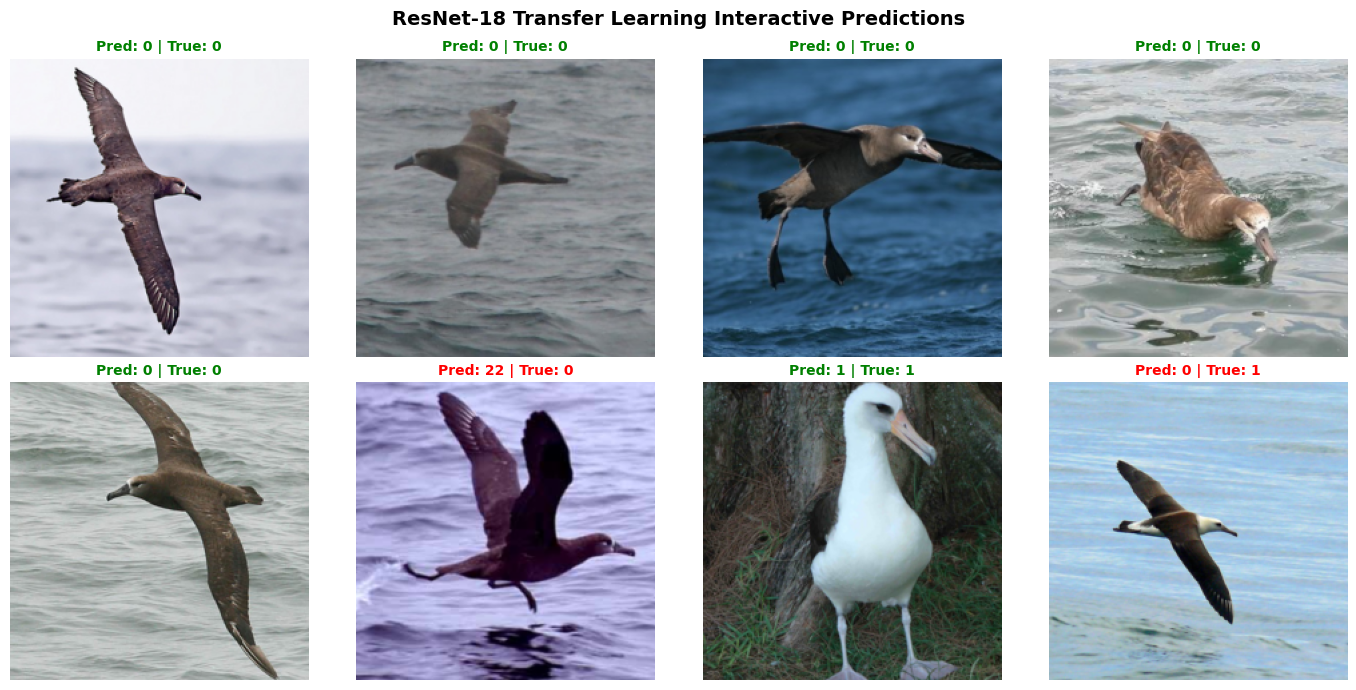

In [5]:
def denormalize(tensor):
    """Reverses ImageNet normalization for visualization."""
    mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
    std = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)
    return (tensor.cpu() * std + mean).clamp(0, 1)

model.eval()
with torch.no_grad():
    logits = model(images.to(device))
    predictions = logits.argmax(dim=1).cpu()

fig, axes = plt.subplots(2, 4, figsize=(14, 7))
fig.suptitle("ResNet-18 Transfer Learning Interactive Predictions", fontsize=14, fontweight="bold")

for idx, ax in enumerate(axes.flat):
    img = denormalize(images[idx]).permute(1, 2, 0).numpy()
    true_cls = labels[idx].item()
    pred_cls = predictions[idx].item()
    
    ax.imshow(img)
    color = "green" if true_cls == pred_cls else "red"
    ax.set_title(f"Pred: {pred_cls} | True: {true_cls}", color=color, fontsize=10, fontweight="bold")
    ax.axis("off")

plt.tight_layout()
plt.show()